# Optimización de hiperparámetros

Antecedente. El A/B dejó al paquete F1 como conjunto de trabajo. La importancia de variables se midió sobre un RandomForest fijo. Aquí se busca una configuración de ese modelo bajo la misma validación.

Qué se hace. Se fija un baseline, se define un espacio acotado y se comparan Random Search y Optuna (TPE). La métrica de selección es F1 macro en validación cruzada. El test no se usa para elegir.

1. Datos y paquete F1.
2. Baseline.
3. Espacio de búsqueda y presupuesto.
4. Random Search.
5. Optuna (TPE).
6. Comparación y top-k.
7. Decisión.

Modelo: RandomForestClassifier.
Paquete: F1.
Etiqueta: candidate_strategy.
Validación: cinco pliegues estratificados, semilla 42.
Métrica: F1 macro.


In [1]:
from __future__ import annotations

import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from optuna.samplers import RandomSampler, TPESampler
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore", category=UserWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

ROOT = Path("..").resolve()
DATA_PATH = ROOT / "data" / "processed" / "features" / "consultas_features.csv"
LOG_DIR = ROOT / "logs"
LOG_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
N_SPLITS = 5
TARGET = "candidate_strategy"
N_TRIALS_RANDOM = 30
N_TRIALS_TPE = 30
TOP_K = 8


## 1. Datos y paquete F1

Fuente: data/processed/features/consultas_features.csv.

Se mantienen las columnas adoptadas en el A/B: forma del texto e intención por reglas. No entran las columnas BM25 del paquete F2.


In [2]:
df = pd.read_csv(DATA_PATH)
y = df[TARGET].astype(str)

F1_NUM = [
    "query_length_chars",
    "query_length_words",
    "question_mark_count",
    "has_multiple_questions",
    "contains_negation",
    "contains_condition",
    "contains_comparison",
    "contains_personal_case",
    "n_intent_families",
    "requires_multiple_sources_rule",
    "requires_personal_context",
    "requires_calculation",
    "requires_rule_validation",
    "requires_temporal_reasoning",
    "contains_academic_entity",
    "contains_administrative_entity",
]
F1_CAT = ["intent_category"]

X = df[F1_NUM + F1_CAT]
print("filas:", len(df))
print("columnas F1:", len(F1_NUM) + len(F1_CAT))
print(y.value_counts().sort_index().to_string())


filas: 196
columnas F1: 17
candidate_strategy
A1    125
A3     27
A5     44


## 2. Baseline

Misma configuración usada en la importancia de variables: 300 árboles, pesos por clase, semilla 42. Sirve de referencia para medir si la búsqueda mueve el F1 macro.


In [3]:
prep = ColumnTransformer(
    [
        ("num", "passthrough", F1_NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), F1_CAT),
    ]
)

baseline_rf = RandomForestClassifier(
    n_estimators=300,
    random_state=SEED,
    class_weight="balanced",
    n_jobs=-1,
)
pipe_base = Pipeline([("prep", prep), ("modelo", baseline_rf)])

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
t0 = time.perf_counter()
f1_base = cross_val_score(pipe_base, X, y, cv=cv, scoring="f1_macro", n_jobs=-1)
t_base = time.perf_counter() - t0

print(f"F1 macro CV baseline: {f1_base.mean():.3f} ± {f1_base.std():.3f}")
print(f"tiempo CV: {t_base:.1f}s")


F1 macro CV baseline: 0.553 ± 0.086
tiempo CV: 2.5s


## 3. Espacio de búsqueda y presupuesto

Seis ejes con rangos acotados. Se permite profundidad sin tope y muestreo completo,
para que el espacio cubra la región del baseline. El resto queda fijo:
class_weight=balanced, n_jobs=-1, random_state=42.

Presupuesto: 30 trials de Random Search y 30 de TPE. Misma partición estratificada en todos los trials.


In [4]:
def make_pipeline(params: dict) -> Pipeline:
    prep_local = ColumnTransformer(
        [
            ("num", "passthrough", F1_NUM),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), F1_CAT),
        ]
    )
    modelo = RandomForestClassifier(
        n_estimators=params["n_estimators"],
        max_depth=params["max_depth"],
        min_samples_split=params["min_samples_split"],
        min_samples_leaf=params["min_samples_leaf"],
        max_features=params["max_features"],
        max_samples=params["max_samples"],
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1,
    )
    return Pipeline([("prep", prep_local), ("modelo", modelo)])


def suggest_params(trial: optuna.Trial) -> dict:
    # profundidad: acotada o sin tope (como el baseline)
    if trial.suggest_categorical("depth_limited", [True, False]):
        max_depth = trial.suggest_int("max_depth", 3, 24)
    else:
        max_depth = None

    # fracción de muestras por árbol: acotada o todas
    if trial.suggest_categorical("subsample", [True, False]):
        max_samples = trial.suggest_float("max_samples", 0.55, 0.95)
    else:
        max_samples = None

    max_features = trial.suggest_categorical(
        "max_features", ["sqrt", "log2", 0.5, 0.8, None]
    )
    return {
        "n_estimators": trial.suggest_int("n_estimators", 100, 500, step=50),
        "max_depth": max_depth,
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 16),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 8),
        "max_features": max_features,
        "max_samples": max_samples,
    }


def objective_factory(cv_local: StratifiedKFold):
    def objective(trial: optuna.Trial) -> float:
        params = suggest_params(trial)
        pipe = make_pipeline(params)
        t_start = time.perf_counter()
        scores = cross_val_score(
            pipe, X, y, cv=cv_local, scoring="f1_macro", n_jobs=-1
        )
        elapsed = time.perf_counter() - t_start
        trial.set_user_attr("f1_std", float(scores.std()))
        trial.set_user_attr("tiempo_s", float(elapsed))
        # guardar params efectivos del modelo (incluye None)
        trial.set_user_attr("n_estimators", params["n_estimators"])
        trial.set_user_attr("max_depth", params["max_depth"])
        trial.set_user_attr("min_samples_split", params["min_samples_split"])
        trial.set_user_attr("min_samples_leaf", params["min_samples_leaf"])
        trial.set_user_attr("max_features", params["max_features"])
        trial.set_user_attr("max_samples", params["max_samples"])
        return float(scores.mean())

    return objective


print("espacio:")
print("  n_estimators: 100..500 (paso 50)")
print("  max_depth: 3..24 o None")
print("  min_samples_split: 2..16")
print("  min_samples_leaf: 1..8")
print("  max_features: {sqrt, log2, 0.5, 0.8, None}")
print("  max_samples: 0.55..0.95 o None")
print(f"presupuesto: {N_TRIALS_RANDOM} random + {N_TRIALS_TPE} TPE")


espacio:
  n_estimators: 100..500 (paso 50)
  max_depth: 3..24 o None
  min_samples_split: 2..16
  min_samples_leaf: 1..8
  max_features: {sqrt, log2, 0.5, 0.8, None}
  max_samples: 0.55..0.95 o None
presupuesto: 30 random + 30 TPE


## 4. Random Search

Muestreo uniforme del espacio. Sirve de calentamiento y de contraste frente a TPE.


In [5]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
objective = objective_factory(cv)

study_random = optuna.create_study(
    direction="maximize",
    sampler=RandomSampler(seed=SEED),
    study_name="rf_f1_random",
)
t0 = time.perf_counter()
study_random.optimize(objective, n_trials=N_TRIALS_RANDOM, show_progress_bar=False)
t_random = time.perf_counter() - t0

print(f"mejor F1 macro (random): {study_random.best_value:.3f}")
print("mejores params:", study_random.best_params)
print(f"tiempo total: {t_random:.1f}s")


mejor F1 macro (random): 0.543
mejores params: {'depth_limited': True, 'max_depth': 19, 'subsample': False, 'max_features': None, 'n_estimators': 200, 'min_samples_split': 9, 'min_samples_leaf': 8}
tiempo total: 12.3s


## 5. Optuna (TPE)

Mismo espacio y misma CV. El sampler TPE prioriza zonas prometedoras a partir del historial de trials.


In [6]:
study_tpe = optuna.create_study(
    direction="maximize",
    sampler=TPESampler(seed=SEED, multivariate=True),
    study_name="rf_f1_tpe",
)
t0 = time.perf_counter()
study_tpe.optimize(objective, n_trials=N_TRIALS_TPE, show_progress_bar=False)
t_tpe = time.perf_counter() - t0

print(f"mejor F1 macro (TPE): {study_tpe.best_value:.3f}")
print("mejores params:", study_tpe.best_params)
print(f"tiempo total: {t_tpe:.1f}s")


mejor F1 macro (TPE): 0.545
mejores params: {'depth_limited': False, 'subsample': False, 'max_features': None, 'n_estimators': 500, 'min_samples_split': 8, 'min_samples_leaf': 8}
tiempo total: 10.7s


## 6. Comparación y top-k

Se reúnen los trials de ambos estudios. La curva muestra el mejor F1 macro acumulado por trial. La importancia de hiperparámetros proviene del estudio TPE.


In [7]:
def trials_frame(study: optuna.Study, metodo: str) -> pd.DataFrame:
    rows = []
    for t in study.trials:
        if t.state.name != "COMPLETE":
            continue
        row = {
            "metodo": metodo,
            "trial": t.number,
            "f1_macro_mean": t.value,
            "f1_macro_std": t.user_attrs.get("f1_std"),
            "tiempo_s": t.user_attrs.get("tiempo_s"),
            "n_estimators": t.user_attrs.get("n_estimators"),
            "max_depth": t.user_attrs.get("max_depth"),
            "min_samples_split": t.user_attrs.get("min_samples_split"),
            "min_samples_leaf": t.user_attrs.get("min_samples_leaf"),
            "max_features": t.user_attrs.get("max_features"),
            "max_samples": t.user_attrs.get("max_samples"),
        }
        rows.append(row)
    return pd.DataFrame(rows)


df_rand = trials_frame(study_random, "random")
df_tpe = trials_frame(study_tpe, "tpe")
df_all = pd.concat([df_rand, df_tpe], ignore_index=True)

def best_params_effective(study: optuna.Study) -> dict:
    t = study.best_trial
    return {
        "n_estimators": t.user_attrs.get("n_estimators"),
        "max_depth": t.user_attrs.get("max_depth"),
        "min_samples_split": t.user_attrs.get("min_samples_split"),
        "min_samples_leaf": t.user_attrs.get("min_samples_leaf"),
        "max_features": t.user_attrs.get("max_features"),
        "max_samples": t.user_attrs.get("max_samples"),
    }


params_random = best_params_effective(study_random)
params_tpe = best_params_effective(study_tpe)

resumen = pd.DataFrame(
    [
        {
            "config": "baseline",
            "f1_macro_mean": f1_base.mean(),
            "f1_macro_std": f1_base.std(),
            "tiempo_s": t_base,
            "n_estimators": 300,
            "max_depth": None,
            "min_samples_split": 2,
            "min_samples_leaf": 1,
            "max_features": "sqrt",
            "max_samples": None,
        },
        {
            "config": "best_random",
            "f1_macro_mean": study_random.best_value,
            "f1_macro_std": study_random.best_trial.user_attrs.get("f1_std"),
            "tiempo_s": study_random.best_trial.user_attrs.get("tiempo_s"),
            **params_random,
        },
        {
            "config": "best_tpe",
            "f1_macro_mean": study_tpe.best_value,
            "f1_macro_std": study_tpe.best_trial.user_attrs.get("f1_std"),
            "tiempo_s": study_tpe.best_trial.user_attrs.get("tiempo_s"),
            **params_tpe,
        },
    ]
)

display(resumen.round(3))

top = (
    df_all.sort_values("f1_macro_mean", ascending=False)
    .head(TOP_K)
    .reset_index(drop=True)
)
display(top.round(3))


,config,f1_macro_mean,f1_macro_std,tiempo_s,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,max_samples
0,baseline,0.553,0.086,2.508,300,NaN,2,1,sqrt,None
1,best_random,0.543,0.048,0.264,200,19.0,9,8,NaN,None
2,best_tpe,0.545,0.059,0.592,500,NaN,8,8,NaN,None


,metodo,trial,f1_macro_mean,f1_macro_std,tiempo_s,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,max_samples
0,tpe,25,0.545,0.059,0.592,500,NaN,8,8,None,NaN
1,tpe,28,0.545,0.059,0.684,500,NaN,8,8,None,NaN
2,tpe,27,0.545,0.059,0.618,500,NaN,7,8,None,NaN
3,tpe,26,0.545,0.059,0.583,500,NaN,6,8,None,NaN
4,random,7,0.543,0.048,0.264,200,19.0,9,8,None,NaN
5,tpe,12,0.543,0.048,0.254,200,NaN,13,8,None,NaN
6,tpe,7,0.543,0.048,0.259,200,19.0,9,8,None,NaN
7,tpe,23,0.538,0.049,0.418,350,NaN,14,8,None,NaN


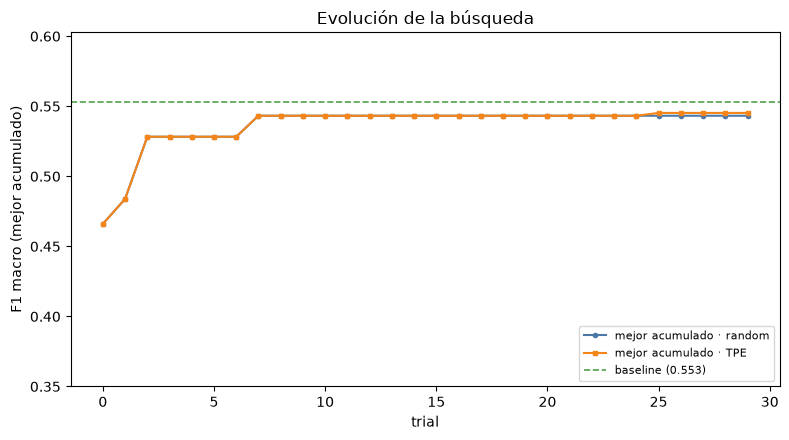

In [8]:
def best_so_far(values: list[float]) -> np.ndarray:
    out = np.empty(len(values), dtype=float)
    best = -np.inf
    for i, v in enumerate(values):
        best = max(best, v)
        out[i] = best
    return out


fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(
    df_rand["trial"],
    best_so_far(df_rand["f1_macro_mean"].tolist()),
    marker="o",
    markersize=3,
    label="mejor acumulado · random",
    color="#4C78A8",
)
ax.plot(
    df_tpe["trial"],
    best_so_far(df_tpe["f1_macro_mean"].tolist()),
    marker="s",
    markersize=3,
    label="mejor acumulado · TPE",
    color="#F58518",
)
ax.axhline(
    f1_base.mean(),
    color="#54A24B",
    linestyle="--",
    linewidth=1.2,
    label=f"baseline ({f1_base.mean():.3f})",
)
ax.set_xlabel("trial")
ax.set_ylabel("F1 macro (mejor acumulado)")
ax.set_title("Evolución de la búsqueda")
ax.legend(loc="lower right", fontsize=8)
ax.set_ylim(0.35, max(df_all["f1_macro_mean"].max(), f1_base.mean()) + 0.05)
fig.tight_layout()
fig.savefig(FIG_DIR / "semana8_hpo_evolucion.png", dpi=150, bbox_inches="tight")
plt.show()


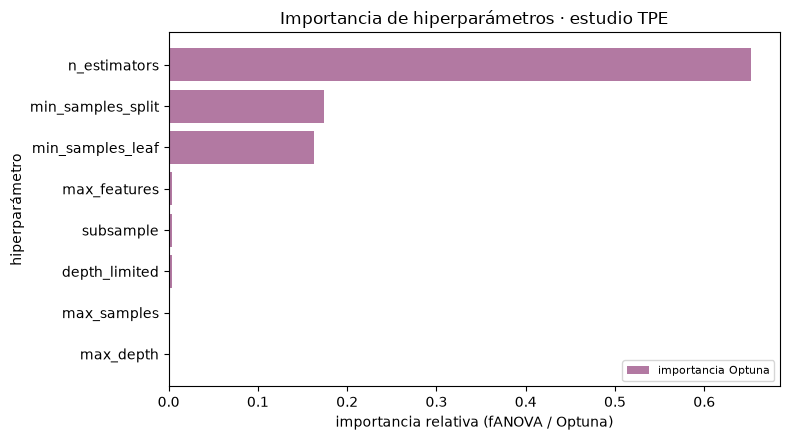

,importancia
n_estimators,0.652
min_samples_split,0.174
min_samples_leaf,0.163
max_features,0.004
depth_limited,0.003
subsample,0.003
max_depth,0.000
max_samples,0.000


In [9]:
# importancia de hiperparámetros (TPE)
try:
    importancia = optuna.importance.get_param_importances(study_tpe)
    imp_series = pd.Series(importancia).sort_values(ascending=True)

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.barh(imp_series.index.astype(str), imp_series.values, color="#B279A2")
    ax.set_xlabel("importancia relativa (fANOVA / Optuna)")
    ax.set_ylabel("hiperparámetro")
    ax.set_title("Importancia de hiperparámetros · estudio TPE")
    ax.legend(["importancia Optuna"], loc="lower right", fontsize=8)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "semana8_hpo_importancia.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(imp_series.sort_values(ascending=False).rename("importancia").to_frame().round(3))
except Exception as exc:
    print("no se pudo calcular importancia:", type(exc).__name__, exc)


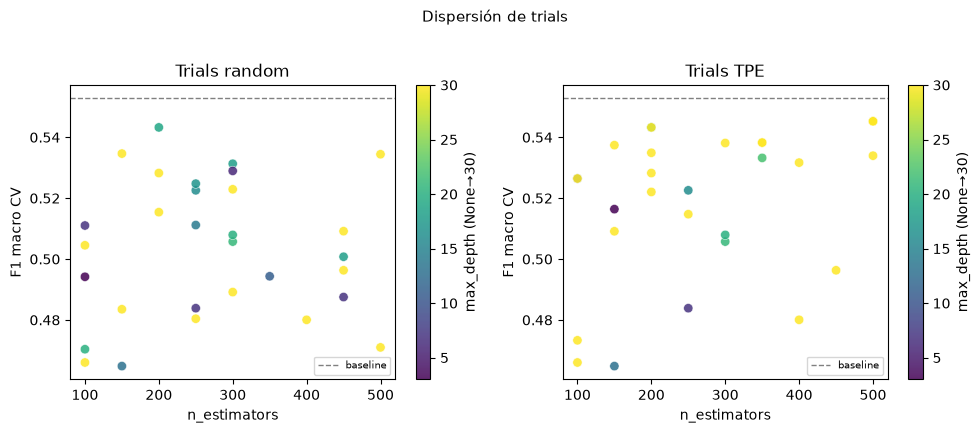

In [10]:
# dispersión de trials: F1 vs n_estimators (color = profundidad efectiva)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

for ax, metodo, frame in [
    (axes[0], "random", df_rand),
    (axes[1], "TPE", df_tpe),
]:
    depth_plot = frame["max_depth"].fillna(30)
    sc = ax.scatter(
        frame["n_estimators"],
        frame["f1_macro_mean"],
        c=depth_plot,
        cmap="viridis",
        s=45,
        alpha=0.85,
        edgecolors="white",
        linewidths=0.4,
    )
    ax.axhline(f1_base.mean(), color="gray", linestyle="--", linewidth=1, label="baseline")
    ax.set_xlabel("n_estimators")
    ax.set_ylabel("F1 macro CV")
    ax.set_title(f"Trials {metodo}")
    cbar = fig.colorbar(sc, ax=ax)
    cbar.set_label("max_depth (None→30)")
    ax.legend(loc="lower right", fontsize=7)

fig.suptitle("Dispersión de trials", y=1.02, fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "semana8_hpo_dispersion.png", dpi=150, bbox_inches="tight")
plt.show()


## 7. Decisión

Se elige la configuración con mayor F1 macro media en CV. Ante empate práctico, se prefiere
la más estable (menor desviación entre pliegues) o la más simple.

La config ganadora se congela para el siguiente sprint.


In [11]:
# elegir ganadora entre baseline, best_random y best_tpe
candidatos = {
    "baseline": {
        "f1": float(f1_base.mean()),
        "std": float(f1_base.std()),
        "params": {
            "n_estimators": 300,
            "max_depth": None,
            "min_samples_split": 2,
            "min_samples_leaf": 1,
            "max_features": "sqrt",
            "max_samples": None,
        },
    },
    "best_random": {
        "f1": float(study_random.best_value),
        "std": float(study_random.best_trial.user_attrs.get("f1_std", np.nan)),
        "params": params_random,
    },
    "best_tpe": {
        "f1": float(study_tpe.best_value),
        "std": float(study_tpe.best_trial.user_attrs.get("f1_std", np.nan)),
        "params": params_tpe,
    },
}

ganadora_nombre = max(candidatos, key=lambda k: candidatos[k]["f1"])
ganadora = candidatos[ganadora_nombre]

resto = sorted(
    ((k, v) for k, v in candidatos.items() if k != ganadora_nombre),
    key=lambda kv: kv[1]["f1"],
    reverse=True,
)
respaldo_nombre, respaldo = resto[0]

print("ganadora:", ganadora_nombre)
print(f"F1 macro: {ganadora['f1']:.3f} ± {ganadora['std']:.3f}")
print("params:", ganadora["params"])
print()
print("respaldo:", respaldo_nombre)
print(f"F1 macro: {respaldo['f1']:.3f} ± {respaldo['std']:.3f}")
print("params:", respaldo["params"])
print()
delta = ganadora["f1"] - float(f1_base.mean())
print(f"delta vs baseline: {delta:+.3f}")


ganadora: baseline
F1 macro: 0.553 ± 0.086
params: {'n_estimators': 300, 'max_depth': None, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_samples': None}

respaldo: best_tpe
F1 macro: 0.545 ± 0.059
params: {'n_estimators': 500, 'max_depth': None, 'min_samples_split': 8, 'min_samples_leaf': 8, 'max_features': None, 'max_samples': None}

delta vs baseline: +0.000


In [12]:
# logs
df_all.to_csv(LOG_DIR / "hpo_runs.csv", index=False)
resumen.to_csv(LOG_DIR / "hpo_resumen.csv", index=False)
top.to_csv(LOG_DIR / "hpo_topk.csv", index=False)

decision = pd.DataFrame(
    [
        {
            "rol": "ganadora",
            "config": ganadora_nombre,
            "f1_macro_mean": ganadora["f1"],
            "f1_macro_std": ganadora["std"],
            **{f"hp_{k}": v for k, v in ganadora["params"].items()},
        },
        {
            "rol": "respaldo",
            "config": respaldo_nombre,
            "f1_macro_mean": respaldo["f1"],
            "f1_macro_std": respaldo["std"],
            **{f"hp_{k}": v for k, v in respaldo["params"].items()},
        },
        {
            "rol": "baseline",
            "config": "baseline",
            "f1_macro_mean": float(f1_base.mean()),
            "f1_macro_std": float(f1_base.std()),
            **{f"hp_{k}": v for k, v in candidatos["baseline"]["params"].items()},
        },
    ]
)
decision.to_csv(LOG_DIR / "hpo_decision.csv", index=False)

print("logs en", LOG_DIR)
print(decision[["rol", "config", "f1_macro_mean", "f1_macro_std"]].round(3).to_string(index=False))


logs en /Users/cesarsanchez/Documents/04-archivo/01-educacion/01-universidad/1_FIIS_UNI/3_Term-III/Investigacion 1/Investigacion-Tesis/3_Sustentacion/3_entregable_curso_tesis/semana8/logs
     rol   config  f1_macro_mean  f1_macro_std
ganadora baseline          0.553         0.086
respaldo best_tpe          0.545         0.059
baseline baseline          0.553         0.086
